In [80]:
from pathlib import Path
from pydrive2.auth import GoogleAuth
from pydrive2.drive import GoogleDrive
from PyPDF2 import PdfReader
import io
import os
import fitz  # PyMuPDF
from pprint import pprint
from collections import Counter
from tempfile import TemporaryDirectory
from docx import Document

import pandas as pd
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

import re
import networkx as nx
import json
from pathlib import Path
import matplotlib.pyplot as plt

import requests
from fastapi import FastAPI
from pydantic import BaseModel
import nest_asyncio
import uvicorn

In [ ]:
# client_secrets.json lives in the repo root, not next to this notebook
secrets = next(p / "client_secrets.json" for p in [Path.cwd(), *Path.cwd().parents] if (p / "client_secrets.json").exists())

gauth = GoogleAuth()
gauth.settings["client_config_file"] = str(secrets)
gauth.settings["get_refresh_token"] = True  # lets the saved login be renewed silently
creds_file = str(secrets.parent / "credentials.json")

gauth.LoadCredentialsFile(creds_file)  # reuse saved login if present
if gauth.credentials is None:
    gauth.LocalWebserverAuth()  # first time only: opens browser
elif gauth.access_token_expired:
    gauth.Refresh()
else:
    gauth.Authorize()
gauth.SaveCredentialsFile(creds_file)

drive = GoogleDrive(gauth)

file_list = drive.ListFile({
    "q": "trashed=false"
}).GetList()

for file in file_list:
        print(file["title"], file["id"], file["mimeType"])

In [5]:
### Get Folder ID by folder name 

def get_folder_id_by_name(drive, folder_name):
    file_list = drive.ListFile(
        {
            'q': "title='" + folder_name + "' and mimeType='application/vnd.google-apps.folder' and trashed=false",
            'corpora': 'allDrives',
            'includeItemsFromAllDrives': True,
            'supportsAllDrives': True,
        }).GetList()
    if file_list != []:
        return file_list[0]['id']
    return None

In [ ]:

from pprint import pprint

FOLDER_MIME_TYPE = "application/vnd.google-apps.folder"


def get_folder_contents(drive, folder_id):
    contents = {}

    file_list = drive.ListFile({
        "q": f"'{folder_id}' in parents and trashed=false"
    }).GetList()

    for file in file_list:
        name = file["title"]

        # Ignore macOS system files
        if name == ".DS_Store":
            continue

        if file["mimeType"] == FOLDER_MIME_TYPE:
            # Recursively retrieve subfolder contents
            contents[name] = get_folder_contents(
                drive, file["id"]
            )
        else:
            # Store PDFs and all other file types
            contents[name] = {
                "id": file["id"],
                "title": file["title"],
                "mimeType": file["mimeType"]
            }

    return contents


# Main folders
target_folder = {
    "FastAPI": "",
    "Langchain": "",
    "Research Paper": ""
}

# Build the nested dictionary
for name in target_folder:
    folder_id = get_folder_id_by_name(drive, name)

    if folder_id:
        target_folder[name] = get_folder_contents(
            drive, folder_id
        )
    else:
        print(f"Folder not found: {name}")

# Display the complete structure
pprint(target_folder)


In [7]:
target_folder['Langchain']['Reflexion: Language Agents with Verbal Reinforcement Learning']

{'id': '1XGL8TixKAQT300e_dq0-50IO1-Jw2NyL',
 'title': 'Reflexion: Language Agents with Verbal Reinforcement Learning',
 'mimeType': 'application/pdf'}

In [42]:
def collect_all_files(contents, path=""):
    """Collect file metadata from all nested folders."""
    files = []

    for name, item in contents.items():
        current_path = f"{path}/{name}".strip("/")

        if not isinstance(item, dict):
            continue

        if "mimeType" not in item:
            # Recursively inspect subfolders
            files.extend(
                collect_all_files(item, current_path)
            )
        else:
            files.append({
                "path": current_path,
                "name": item["title"],
                "id": item["id"],
                "mimeType": item["mimeType"],
                "extension":  os.path.splitext(name)[1].lower()
            })

    return files

In [40]:
from collections import Counter

all_files = collect_all_files(target_folder)

file_types = Counter(
    file["mimeType"] for file in all_files
)

odd_file = Counter(
    file["name"] for file in all_files if file["mimeType"] ==  'application/octet-stream'
)

print(file_types)

Counter({'text/x-python': 111, 'application/octet-stream': 60, 'application/pdf': 40, 'application/x-shellscript': 12, 'text/html': 8, 'text/javascript': 4, 'text/markdown': 3, 'text/x-sql': 2, 'text/css': 2, 'application/x-perl': 1, 'application/x-python-code': 1, 'text/plain': 1, 'application/vnd.openxmlformats-officedocument.wordprocessingml.document': 1, 'text/csv': 1})


In [54]:
# --------------------------------------------------
# 1. Define the file types we want to extract
# --------------------------------------------------

PRIORITY_MIME_TYPES = {
    "application/pdf",
    "text/x-python",
    "text/markdown",
    "application/vnd.openxmlformats-officedocument.wordprocessingml.document",
    "text/plain",
    "text/csv",
}

# Fallback MIME types based on file extensions
EXTENSION_TO_MIME = {
    ".pdf": "application/pdf",
    ".py": "text/x-python",
    ".md": "text/markdown",
    ".docx": "application/vnd.openxmlformats-officedocument.wordprocessingml.document",
    ".txt": "text/plain",
    ".csv": "text/csv",
}


# --------------------------------------------------
# 2. Extract text from one Google Drive file
# --------------------------------------------------

def extract_file_text(drive, file_metadata):
    """Download one Google Drive file and extract its text."""

    file_id = file_metadata["id"]
    filename = (
        file_metadata.get("title")
        or file_metadata.get("name", "")
    )

    mime_type = file_metadata.get("mimeType", "")

    # Ignore macOS metadata files
    if filename == ".DS_Store":
        return None

    # Infer the MIME type if missing or generic
    if mime_type not in PRIORITY_MIME_TYPES:
        inferred_mime = EXTENSION_TO_MIME.get(
            Path(filename).suffix.lower()
        )

        if inferred_mime:
            mime_type = inferred_mime

    # Skip unsupported file types
    if mime_type not in PRIORITY_MIME_TYPES:
        return None

    try:
        with TemporaryDirectory() as temp_dir:

            # Determine a suitable temporary file extension
            extension = Path(filename).suffix.lower()

            if not extension:
                extension = {
                    "application/pdf": ".pdf",
                    "application/vnd.openxmlformats-officedocument.wordprocessingml.document": ".docx",
                    "text/x-python": ".py",
                    "text/markdown": ".md",
                    "text/plain": ".txt",
                    "text/csv": ".csv",
                }[mime_type]

            local_path = Path(temp_dir) / f"download{extension}"

            # Download the file from Google Drive
            drive_file = drive.CreateFile({"id": file_id})
            drive_file.GetContentFile(str(local_path))

            # ------------------------------------------
            # PDF
            # ------------------------------------------
            if mime_type == "application/pdf":

                page_contents = []

                with fitz.open(str(local_path)) as pdf:
                    for page_number, page in enumerate(
                        pdf, start=1
                    ):
                        page_text = page.get_text()

                        if page_text.strip():
                            page_contents.append(
                                f"[Page {page_number}]\n{page_text}"
                            )

                content = "\n\n".join(page_contents)

            # ------------------------------------------
            # Word document
            # ------------------------------------------
            elif mime_type == (
                "application/vnd.openxmlformats-officedocument.wordprocessingml.document"
            ):

                doc = Document(str(local_path))
                parts = []

                # Extract paragraphs
                for paragraph in doc.paragraphs:
                    if paragraph.text.strip():
                        parts.append(paragraph.text)

                # Extract tables
                for table in doc.tables:
                    for row in table.rows:
                        row_text = " | ".join(
                            cell.text.strip()
                            for cell in row.cells
                        )
                        parts.append(row_text)

                content = "\n".join(parts)

            # ------------------------------------------
            # CSV
            # ------------------------------------------
            elif mime_type == "text/csv":

                # Read values as strings and handle empty cells
                df = pd.read_csv(
                    local_path,
                    dtype=str,
                    keep_default_na=False,
                    encoding="utf-8-sig",
                )

                # Convert column names and rows to readable text
                content = df.to_string(index=False)

            # ------------------------------------------
            # Python, Markdown, and plain text
            # ------------------------------------------
            else:

                content = local_path.read_text(
                    encoding="utf-8",
                    errors="replace",
                )

        # Return extracted information and metadata
        return {
            "id": file_id,
            "title": filename,
            "mimeType": mime_type,
            "path": file_metadata.get("path", ""),
            "content": content,
            "character_count": len(content),
        }

    except Exception as error:
        print(f"Error extracting {filename}: {error}")
        return None


# --------------------------------------------------
# 3. Extract all supported files
# --------------------------------------------------

def extract_priority_files(drive, all_files):
    """Extract all supported files from a flat metadata list."""

    extracted_files = []

    for file_metadata in all_files:
        result = extract_file_text(drive, file_metadata)

        if result is not None:
            extracted_files.append(result)

    # Report extraction summary
    print(f"Successfully extracted: {len(extracted_files)} files")

    print("\nFiles extracted by MIME type:")

    for mime_type, count in Counter(
        item["mimeType"] for item in extracted_files
    ).items():
        print(f"{mime_type}: {count}")

    # Report files with no extractable text
    empty_files = [
        item["title"]
        for item in extracted_files
        if not item["content"].strip()
    ]

    if empty_files:
        print("\nFiles with empty extracted text:")
        for filename in empty_files:
            print(f"- {filename}")

    return extracted_files


In [55]:
# --------------------------------------------------
# 4. Run the extraction
# --------------------------------------------------

rag_documents = extract_priority_files(drive, all_files)

Successfully extracted: 157 files

Files extracted by MIME type:
text/x-python: 111
text/markdown: 3
text/plain: 1
application/pdf: 40
application/vnd.openxmlformats-officedocument.wordprocessingml.document: 1
text/csv: 1

Files with empty extracted text:
- __init__.py
- __init__.py
- __init__.py
- __init__.py
- __init__.py
- __init__.py
- __init__.py
- __init__.py
- __init__.py
- __init__.py


In [87]:
# Convert RAG documents into a DataFrame
df = pd.DataFrame(rag_documents)

# Export to CSV
output_file = "rag_documents.csv"

df.to_csv(
    output_file,
    index=False,
    encoding="utf-8-sig",
)

print(f"Exported {len(rag_documents)} documents to {output_file}")


Exported 157 documents to rag_documents.csv


In [70]:
CONCEPTS = [
    "Python",
    "FastAPI",
    "LangChain",
    "LangGraph",
    "RAG",
    "machine learning",
    "deep learning",
    "natural language processing",
    "SQL",
    "API",
    "knowledge graph",
    "vector database",
    "embeddings",
    "neural network",
    "data science",
]


def build_knowledge_graph(rag_documents):
    """Build a graph from extracted document text and metadata."""

    graph = nx.MultiDiGraph()

    for document in rag_documents:
        file_id = str(document["id"])
        title = document.get("title", "Untitled")
        mime_type = document.get("mimeType", "unknown")
        content = document.get("content", "")

        # 1. Create a document node
        doc_node = f"document:{file_id}"

        graph.add_node(
            doc_node,
            node_type="document",
            title=title,
            mime_type=mime_type,
            character_count=len(content),
        )

        # 2. Create a file-type node
        type_node = f"type:{mime_type}"

        graph.add_node(
            type_node,
            node_type="file_type",
            name=mime_type,
        )

        graph.add_edge(
            doc_node,
            type_node,
            relationship="HAS_TYPE",
        )

        # 3. Detect concepts in the title and content
        searchable_text = f"{title}\n{content}"

        for concept in CONCEPTS:
            pattern = (
                r"(?<!\w)"
                + re.escape(concept)
                + r"(?!\w)"
            )

            if re.search(
                pattern,
                searchable_text,
                flags=re.IGNORECASE,
            ):
                concept_node = f"concept:{concept.lower()}"

                graph.add_node(
                    concept_node,
                    node_type="concept",
                    name=concept,
                )

                graph.add_edge(
                    doc_node,
                    concept_node,
                    relationship="MENTIONS",
                )

    return graph


# Build the graph
knowledge_graph = build_knowledge_graph(rag_documents)

print("Nodes:", knowledge_graph.number_of_nodes())
print("Edges:", knowledge_graph.number_of_edges())
print("\nNode types:")

from collections import Counter

print(Counter(
    data["node_type"]
    for _, data in knowledge_graph.nodes(data=True)
))

Nodes: 176
Edges: 368

Node types:
Counter({'document': 157, 'concept': 13, 'file_type': 6})


In [75]:
def retrieve_from_graph(question, knowledge_graph, rag_documents, max_docs=4):
    question = question.lower()

    # Find matching topic and concept nodes
    matched_nodes = []

    for node, attrs in knowledge_graph.nodes(data=True):
        if attrs.get("node_type") in {"topic", "concept"}:
            name = str(attrs.get("name", "")).lower()

            if name and name in question:
                matched_nodes.append(node)

    # Find documents connected to those nodes
    document_ids = set()

    for node in matched_nodes:
        for predecessor in knowledge_graph.predecessors(node):
            attrs = knowledge_graph.nodes[predecessor]

            if attrs.get("node_type") == "document":
                document_ids.add(predecessor.split(":", 1)[1])

    # Retrieve the actual text from your extracted documents
    documents_by_id = {
        str(doc["id"]): doc for doc in rag_documents
    }

    results = []

    for doc_id in document_ids:
        doc = documents_by_id.get(doc_id)

        if doc:
            results.append({
                "title": doc["title"],
                "content": doc["content"][:2500],
            })

        if len(results) >= max_docs:
            break

    return results

In [81]:
app = FastAPI(title="Knowledge Graph Chatbot")


class Message(BaseModel):
    text: str


@app.post("/chat")
def send_message(message: Message):
    # Retrieve documents from your existing knowledge graph
    documents = retrieve_from_graph(
        message.text,
        knowledge_graph,
        rag_documents,
    )

    context = "\n\n".join(
        f"Document: {doc['title']}\n{doc['content']}"
        for doc in documents
    )

    if not context:
        context = "No relevant documents were found."

    prompt = f"""
Answer the question using the context below.
If the answer is not in the context, say so.
Do not invent information.

Context:
{context}

Question:
{message.text}
"""

    response = requests.post(
        "http://localhost:11434/api/chat",
        json={
            "model": "gemma3",
            "messages": [
                {"role": "user", "content": prompt}
            ],
            "stream": False,
        },
        timeout=120,
    )
    response.raise_for_status()

    return {
        "message": response.json()["message"]["content"],
        "sources": [doc["title"] for doc in documents],
    }


nest_asyncio.apply()

config = uvicorn.Config(
    app,
    host="127.0.0.1",
    port=8000,
    log_level="info",
)
server = uvicorn.Server(config)

await server.serve()


INFO:     Started server process [59298]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://127.0.0.1:8000 (Press CTRL+C to quit)


INFO:     127.0.0.1:60838 - "GET / HTTP/1.1" 404 Not Found
INFO:     127.0.0.1:60838 - "GET /favicon.ico HTTP/1.1" 404 Not Found
INFO:     127.0.0.1:60853 - "GET /docs HTTP/1.1" 200 OK
INFO:     127.0.0.1:60853 - "GET /openapi.json HTTP/1.1" 200 OK
INFO:     127.0.0.1:60854 - "POST /chat HTTP/1.1" 200 OK


INFO:     Shutting down
INFO:     Waiting for application shutdown.
INFO:     Application shutdown complete.
INFO:     Finished server process [59298]


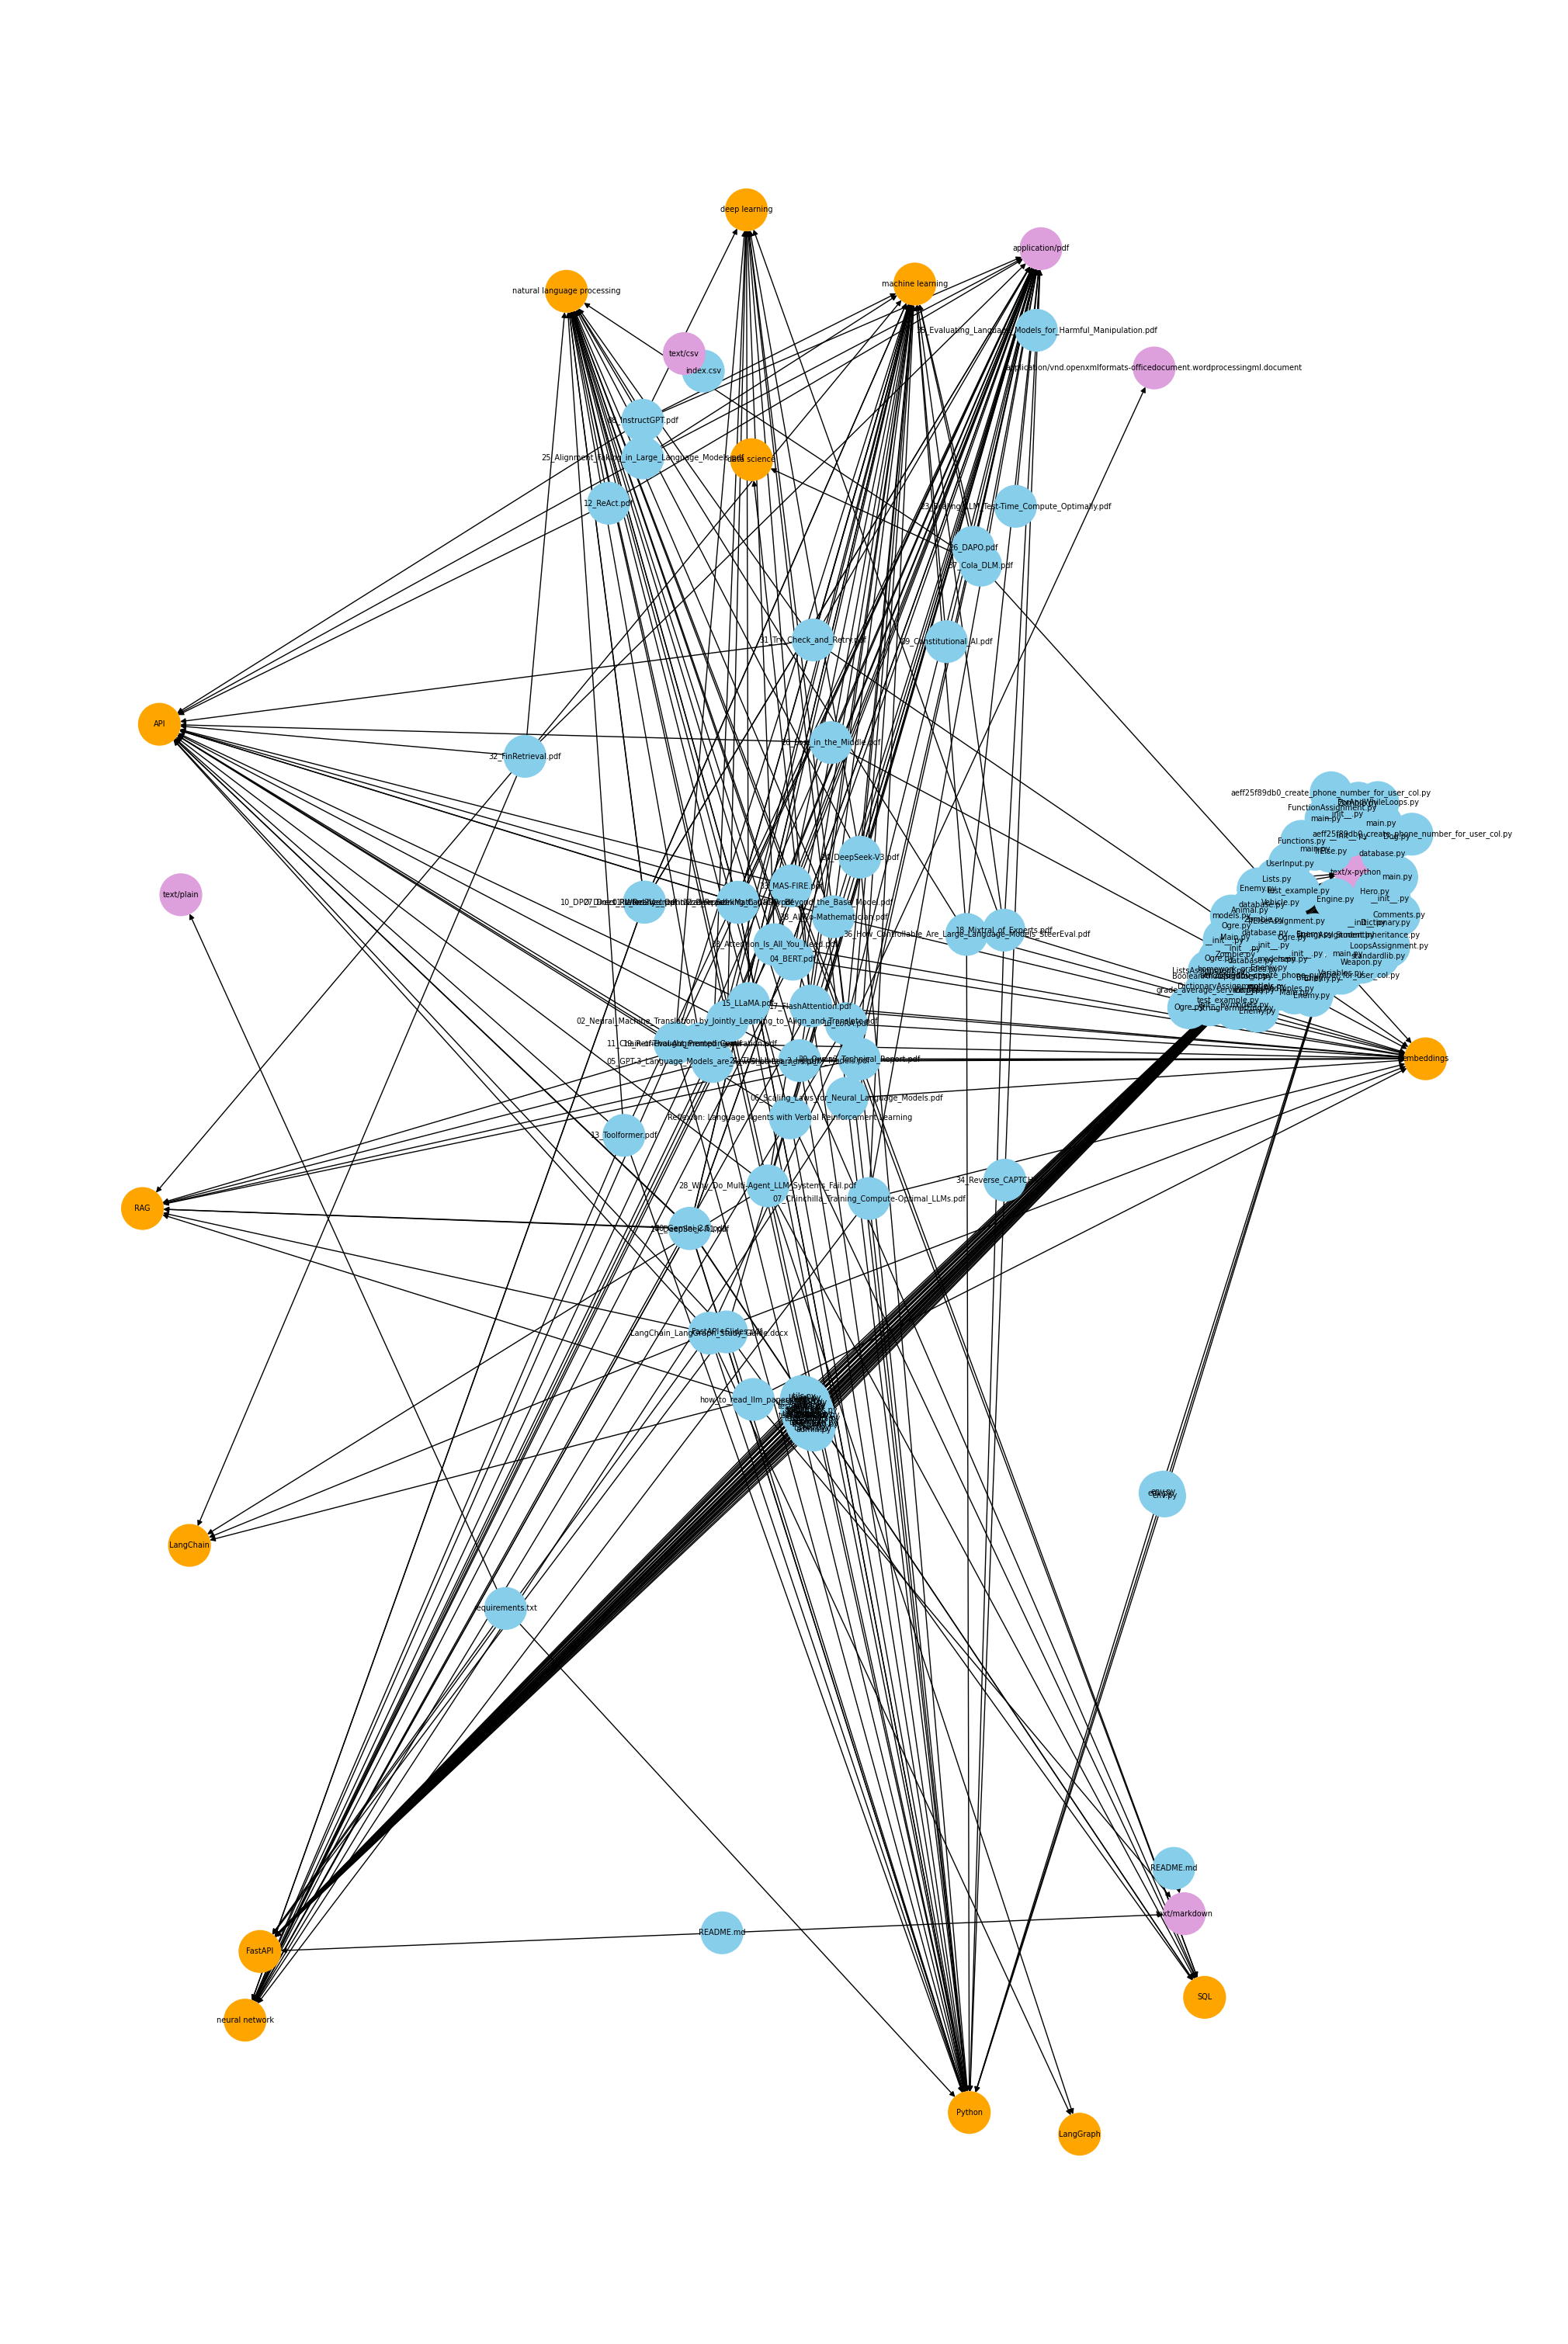

In [72]:
# Visualize the knowledge graph
plt.figure(figsize=(20, 30))

pos = nx.spring_layout(knowledge_graph, seed=42)

# Color nodes by type
colors = {
    "document": "skyblue",
    "topic": "lightgreen",
    "concept": "orange",
    "file_type": "plum",
}

node_colors = [
    colors.get(knowledge_graph.nodes[node].get("node_type"), "gray")
    for node in knowledge_graph.nodes
]

nx.draw(
    knowledge_graph,
    pos,
    with_labels=True,
    labels={
        node: knowledge_graph.nodes[node].get("name")
              or knowledge_graph.nodes[node].get("title", node)
        for node in knowledge_graph.nodes
    },
    node_color=node_colors,
    node_size=1500,
    font_size=7,
    arrows=True,
)

plt.show()
